In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
import matplotlib.pyplot as plt
import numpy as np

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cuda


In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))  # MNIST global men and std values
])

In [3]:
full_train = datasets.MNIST(root='./data', train=True,  download=True, transform=transform);


100%|██████████| 9.91M/9.91M [00:01<00:00, 5.60MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 132kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.24MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.30MB/s]


In [6]:
test_set   = datasets.MNIST(root='./data', train=False, download=True, transform=transform);


In [7]:
val_size   = int(0.1 * len(full_train));
print("Validation Size=====>>>>",val_size);

Validation Size=====>>>> 6000


In [8]:
train_size = len(full_train) - val_size;
print(train_size);

54000


In [9]:
train_set, val_set = random_split(full_train, [train_size, val_size],
                                  generator=torch.Generator().manual_seed(42));

In [10]:
train_loader = DataLoader(train_set, batch_size=64, shuffle=True,  num_workers=2);


In [11]:
val_loader   = DataLoader(val_set,   batch_size=64, shuffle=False, num_workers=2);


In [12]:
test_loader  = DataLoader(test_set,  batch_size=64, shuffle=False, num_workers=2);


In [13]:
print(f'Train: {len(train_set)} | Val: {len(val_set)} | Test: {len(test_set)}')


Train: 54000 | Val: 6000 | Test: 10000


In [26]:
class TinyCNN(nn.Module):
  def __init__(self):

    super(TinyCNN,self).__init__();

    self.conv1 = nn.Sequential(
        nn.Conv2d(1,8,kernel_size=3,padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2)
    );

    self.conv2= nn.Sequential(
        nn.Conv2d(8,16,kernel_size=3,padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2)
    );

    self.conv3= nn.Sequential(
        nn.Conv2d(16,8,kernel_size=3,padding=1),
        nn.ReLU()
    );

    self.fc1= nn.Sequential(
        nn.Linear(8*7*7,64),
        nn.ReLU(),
        nn.Dropout(0.5)
    );

    self.fc2= nn.Linear(64,10);

  def forward(self,x):
    x = self.conv1(x);
    x = self.conv2(x);
    x = self.conv3(x);
    x = x.view(x.size(0),-1);

    x = self.fc1(x);
    x = self.fc2(x);

    return x;

model=TinyCNN().to(device);

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total trainable parameters: {total_params:,}')
print(model)


Total trainable parameters: 28,210
TinyCNN(
  (conv1): Sequential(
    (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv2): Sequential(
    (0): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv3): Sequential(
    (0): Conv2d(16, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
  )
  (fc1): Sequential(
    (0): Linear(in_features=392, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.5, inplace=False)
  )
  (fc2): Linear(in_features=64, out_features=10, bias=True)
)


In [30]:
criteria= nn.CrossEntropyLoss();
optimizer= optim.Adam(model.parameters(),lr=1e-3);

NUM_EPOCHS=15;
history={"train_loss":[],"train_acc":[],"val_loss":[],"val_acc":[]};

def run_epoch(loader,training=True):
  if training == True:
    model.train();
  else:
    model.eval();

  total_loss, correct, total= 0.0,0,0;

  context= torch.enable_grad() if training == True else torch.no_grad();

  with context:
    for images, labels in loader:
      images, labels= images.to(device), labels.to(device);

      if training:
        optimizer.zero_grad();

      outputs= model(images);

      loss= criteria(outputs,labels);

      if training:
        loss.backward();
        optimizer.step();

      total_loss += loss.item() * images.size(0);
      preds= outputs.argmax(dim=1);
      correct += (preds==labels).sum().item();
      total += images.size(0);

  return total_loss/total , correct/total * 100;


print("START TRAINING...............");


for epoch in range(1, NUM_EPOCHS + 1):

    print("===== RUNNING EPOCH ===== ", epoch);
    tr_loss, tr_acc = run_epoch(train_loader, training=True);
    vl_loss, vl_acc = run_epoch(val_loader,   training=False);

    history['train_loss'].append(tr_loss);
    history['val_loss'].append(vl_loss);
    history['train_acc'].append(tr_acc);
    history['val_acc'].append(vl_acc);

    print(f'Epoch [{epoch:02d}/{NUM_EPOCHS}]  '
          f'Train Loss: {tr_loss:.4f}  Train Acc: {tr_acc:.2f}%  '
          f'Val Loss: {vl_loss:.4f}  Val Acc: {vl_acc:.2f}%');




START TRAINING...............
===== RUNNING EPOCH =====  1
Epoch [01/15]  Train Loss: 0.0686  Train Acc: 97.89%  Val Loss: 0.0434  Val Acc: 98.72%
===== RUNNING EPOCH =====  2
Epoch [02/15]  Train Loss: 0.0661  Train Acc: 98.01%  Val Loss: 0.0463  Val Acc: 98.65%
===== RUNNING EPOCH =====  3
Epoch [03/15]  Train Loss: 0.0615  Train Acc: 98.16%  Val Loss: 0.0475  Val Acc: 98.72%
===== RUNNING EPOCH =====  4
Epoch [04/15]  Train Loss: 0.0583  Train Acc: 98.20%  Val Loss: 0.0525  Val Acc: 98.68%
===== RUNNING EPOCH =====  5
Epoch [05/15]  Train Loss: 0.0547  Train Acc: 98.32%  Val Loss: 0.0464  Val Acc: 98.80%
===== RUNNING EPOCH =====  6
Epoch [06/15]  Train Loss: 0.0513  Train Acc: 98.46%  Val Loss: 0.0546  Val Acc: 98.67%
===== RUNNING EPOCH =====  7
Epoch [07/15]  Train Loss: 0.0520  Train Acc: 98.39%  Val Loss: 0.0456  Val Acc: 98.78%
===== RUNNING EPOCH =====  8
Epoch [08/15]  Train Loss: 0.0493  Train Acc: 98.42%  Val Loss: 0.0462  Val Acc: 98.80%
===== RUNNING EPOCH =====  9
Epoch

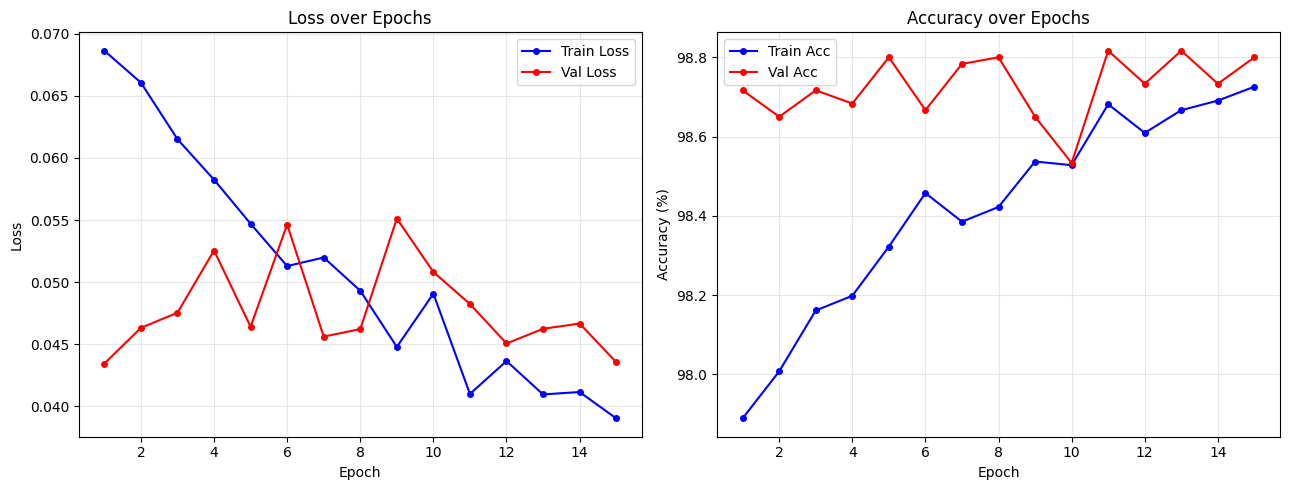

In [31]:
epochs = range(1, NUM_EPOCHS + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Loss plot
ax1.plot(epochs, history['train_loss'], 'b-o', markersize=4, label='Train Loss')
ax1.plot(epochs, history['val_loss'],   'r-o', markersize=4, label='Val Loss')
ax1.set_title('Loss over Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Accuracy plot
ax2.plot(epochs, history['train_acc'], 'b-o', markersize=4, label='Train Acc')
ax2.plot(epochs, history['val_acc'],   'r-o', markersize=4, label='Val Acc')
ax2.set_title('Accuracy over Epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('mnist_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

In [32]:
test_loss, test_acc = run_epoch(test_loader, training=False);
print(f'===== Final Test Results =====');
print(f'Test Loss:     {test_loss:.4f}');
print(f'Test Accuracy: {test_acc:.2f}%');

===== Final Test Results =====
Test Loss:     0.0308
Test Accuracy: 99.05%


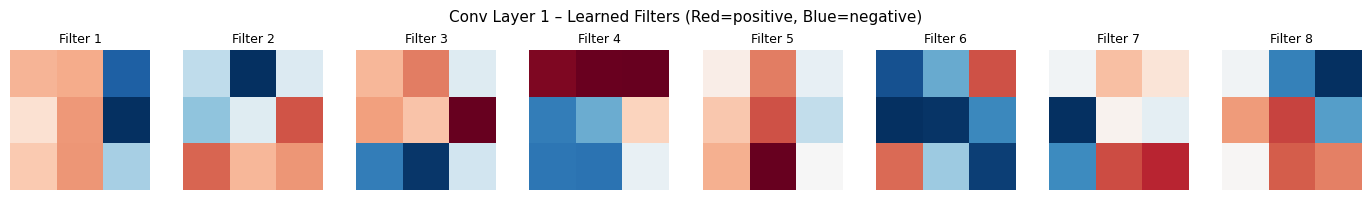

In [33]:
filters = model.conv1[0].weight.data.cpu().numpy()

fig, axes = plt.subplots(1, 8, figsize=(14, 2))
for i, ax in enumerate(axes):
    f = filters[i, 0]
    vmax = np.abs(f).max()
    ax.imshow(f, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
    ax.set_title(f'Filter {i+1}', fontsize=9)
    ax.axis('off')

fig.suptitle('Conv Layer 1 – Learned Filters (Red=positive, Blue=negative)', fontsize=11)
plt.tight_layout()
plt.savefig('conv1_filters.png', dpi=150, bbox_inches='tight')
plt.show()

In [45]:
import zipfile

with zipfile.ZipFile('/content/cmnist.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/')

import os
print(os.listdir('/content/'))

['.config', 'train_biased.pt', 'test_biased.pt', '.ipynb_checkpoints', 'mnist_training_curves.png', 'conv1_filters.png', '__MACOSX', 'cmnist.zip', 'data', 'test_unbiased.pt', 'sample_data']


In [46]:
train_data = torch.load('/content/train_biased.pt', weights_only=False)
print(type(train_data))
print(train_data.keys() if isinstance(train_data, dict) else len(train_data))

<class 'tuple'>
2


In [47]:
print(type(train_data[0]))
print(type(train_data[1]))
print(train_data[0].shape)
print(train_data[1].shape)

<class 'torch.Tensor'>
<class 'torch.Tensor'>
torch.Size([60000, 3, 28, 28])
torch.Size([60000])


In [48]:
train_data    = torch.load('/content/train_biased.pt', weights_only=False)
test_biased   = torch.load('/content/test_biased.pt',  weights_only=False)
test_unbiased = torch.load('/content/test_unbiased.pt', weights_only=False)

from torch.utils.data import TensorDataset

train_dataset          = TensorDataset(train_data[0],    train_data[1])
test_biased_dataset    = TensorDataset(test_biased[0],   test_biased[1])
test_unbiased_dataset  = TensorDataset(test_unbiased[0], test_unbiased[1])

train_loader_c          = DataLoader(train_dataset,         batch_size=64, shuffle=True)
test_biased_loader_c    = DataLoader(test_biased_dataset,   batch_size=64, shuffle=False)
test_unbiased_loader_c  = DataLoader(test_unbiased_dataset, batch_size=64, shuffle=False)

print(f'Train: {len(train_dataset)} | Test Biased: {len(test_biased_dataset)} | Test Unbiased: {len(test_unbiased_dataset)}')

Train: 60000 | Test Biased: 10000 | Test Unbiased: 10000


In [51]:
class TinyCNNColored(nn.Module):
  def __init__(self):

    super(TinyCNNColored,self).__init__();

    self.conv1 = nn.Sequential(
        nn.Conv2d(3,8,kernel_size=3,padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2)
    );

    self.conv2= nn.Sequential(
        nn.Conv2d(8,16,kernel_size=3,padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2)
    );

    self.conv3= nn.Sequential(
        nn.Conv2d(16,8,kernel_size=3,padding=1),
        nn.ReLU()
    );

    self.fc1= nn.Sequential(
        nn.Linear(8*7*7,64),
        nn.ReLU(),
        nn.Dropout(0.5)
    );

    self.fc2= nn.Linear(64,10);

  def forward(self,x):
    x = self.conv1(x);
    x = self.conv2(x);
    x = self.conv3(x);
    x = x.view(x.size(0),-1);

    x = self.fc1(x);
    x = self.fc2(x);

    return x;

model_rgb=TinyCNNColored().to(device);

total_params = sum(p.numel() for p in model_rgb.parameters() if p.requires_grad)
print(f'Total trainable parameters: {total_params:,}')
print(model_rgb)


Total trainable parameters: 28,354
TinyCNNColored(
  (conv1): Sequential(
    (0): Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv2): Sequential(
    (0): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv3): Sequential(
    (0): Conv2d(16, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
  )
  (fc1): Sequential(
    (0): Linear(in_features=392, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.5, inplace=False)
  )
  (fc2): Linear(in_features=64, out_features=10, bias=True)
)


In [52]:
criteria_rgb = nn.CrossEntropyLoss();
optimizer_rgb = optim.Adam(model_rgb.parameters(), lr=1e-3);

NUM_EPOCHS = 15;
history_rgb = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []};

def run_epoch_rgb(loader, training=True):
    if training:
        model_rgb.train();
    else:
        model_rgb.eval();

    total_loss, correct, total = 0.0, 0, 0;

    context = torch.enable_grad() if training else torch.no_grad();

    with context:
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device);

            if training:
                optimizer_rgb.zero_grad();

            outputs = model_rgb(images);
            loss = criteria_rgb(outputs, labels);

            if training:
                loss.backward()
                optimizer_rgb.step()

            total_loss += loss.item() * images.size(0);
            preds = outputs.argmax(dim=1);
            correct += (preds == labels).sum().item();
            total += images.size(0);

    return total_loss / total, correct / total * 100;


print("START TRAINING...");

for epoch in range(1, NUM_EPOCHS + 1):
    tr_loss, tr_acc = run_epoch_rgb(train_loader_c, training=True);

    history_rgb['train_loss'].append(tr_loss);
    history_rgb['train_acc'].append(tr_acc);

    print(f'Epoch [{epoch:02d}/{NUM_EPOCHS}]  '
          f'Train Loss: {tr_loss:.4f}  Train Acc: {tr_acc:.2f}%');

START TRAINING...
Epoch [01/15]  Train Loss: 0.5225  Train Acc: 85.60%
Epoch [02/15]  Train Loss: 0.2224  Train Acc: 94.15%
Epoch [03/15]  Train Loss: 0.1648  Train Acc: 95.41%
Epoch [04/15]  Train Loss: 0.1338  Train Acc: 96.21%
Epoch [05/15]  Train Loss: 0.1112  Train Acc: 96.73%
Epoch [06/15]  Train Loss: 0.0944  Train Acc: 97.30%
Epoch [07/15]  Train Loss: 0.0843  Train Acc: 97.52%
Epoch [08/15]  Train Loss: 0.0707  Train Acc: 97.88%
Epoch [09/15]  Train Loss: 0.0659  Train Acc: 98.11%
Epoch [10/15]  Train Loss: 0.0599  Train Acc: 98.24%
Epoch [11/15]  Train Loss: 0.0553  Train Acc: 98.38%
Epoch [12/15]  Train Loss: 0.0518  Train Acc: 98.48%
Epoch [13/15]  Train Loss: 0.0468  Train Acc: 98.58%
Epoch [14/15]  Train Loss: 0.0460  Train Acc: 98.60%
Epoch [15/15]  Train Loss: 0.0459  Train Acc: 98.67%


In [53]:
model = model_rgb;
test_biased_loss, test_biased_acc = run_epoch(test_biased_loader_c, training=False);

test_unbiased_loss, test_unbiased_acc = run_epoch(test_unbiased_loader_c, training=False)

print(f'===== C-MNIST Test Results =====')
print(f'Biased Test Accuracy:   {test_biased_acc:.2f}%')
print(f'Unbiased Test Accuracy: {test_unbiased_acc:.2f}%')
print(f'Accuracy Drop:          {test_biased_acc - test_unbiased_acc:.2f}%')

===== C-MNIST Test Results =====
Biased Test Accuracy:   99.37%
Unbiased Test Accuracy: 91.84%
Accuracy Drop:          7.53%


In [54]:
from torchvision import datasets, transforms, models;

In [56]:
transform_stl = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],  # ImageNet mean
                         std=[0.229, 0.224, 0.225])    # ImageNet std
]);

train_stl = datasets.STL10(root='./data', split='train', download=True, transform=transform_stl);
test_stl  = datasets.STL10(root='./data', split='test',  download=True, transform=transform_stl);

train_loader_stl = DataLoader(train_stl, batch_size=32, shuffle=True,  num_workers=2);
test_loader_stl  = DataLoader(test_stl,  batch_size=32, shuffle=False, num_workers=2);

print(f'Train: {len(train_stl)} | Test: {len(test_stl)}');
print(f'Classes: {train_stl.classes}');

100%|██████████| 2.64G/2.64G [05:01<00:00, 8.76MB/s]


Train: 5000 | Test: 8000
Classes: ['airplane', 'bird', 'car', 'cat', 'deer', 'dog', 'horse', 'monkey', 'ship', 'truck']


In [57]:
model_resnet = models.resnet18(weights='IMAGENET1K_V1');

for param in model_resnet.parameters():
    param.requires_grad = False;

model_resnet.fc = nn.Linear(512, 10);

model_resnet = model_resnet.to(device);

trainable_params = sum(p.numel() for p in model_resnet.parameters() if p.requires_grad);
total_params      = sum(p.numel() for p in model_resnet.parameters());
print(f'Trainable parameters: {trainable_params:,}');
print(f'Total parameters:     {total_params:,}');
print(f'Frozen parameters:    {total_params - trainable_params:,}');

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 195MB/s]


Trainable parameters: 5,130
Total parameters:     11,181,642
Frozen parameters:    11,176,512


In [58]:
criteria_resnet = nn.CrossEntropyLoss();
optimizer_resnet = optim.Adam(model_resnet.fc.parameters(), lr=1e-3);

NUM_EPOCHS = 10;
history_resnet = {'train_loss': [], 'train_acc': [], 'test_loss': [], 'test_acc': []};

def run_epoch_resnet(loader, training=True):
    if training:
        model_resnet.train();
    else:
        model_resnet.eval();

    total_loss, correct, total = 0.0, 0, 0;

    context = torch.enable_grad() if training else torch.no_grad();

    with context:
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device);

            if training:
                optimizer_resnet.zero_grad();

            outputs = model_resnet(images);
            loss = criteria_resnet(outputs, labels);

            if training:
                loss.backward();
                optimizer_resnet.step();

            total_loss += loss.item() * images.size(0);
            preds = outputs.argmax(dim=1);
            correct += (preds == labels).sum().item();
            total += images.size(0);

    return total_loss / total, correct / total * 100;


print('START TRAINING...');

for epoch in range(1, NUM_EPOCHS + 1):
    tr_loss, tr_acc = run_epoch_resnet(train_loader_stl, training=True);
    ts_loss, ts_acc = run_epoch_resnet(test_loader_stl,  training=False);

    history_resnet['train_loss'].append(tr_loss);
    history_resnet['train_acc'].append(tr_acc);
    history_resnet['test_loss'].append(ts_loss);
    history_resnet['test_acc'].append(ts_acc);

    print(f'Epoch [{epoch:02d}/{NUM_EPOCHS}]  '
          f'Train Loss: {tr_loss:.4f}  Train Acc: {tr_acc:.2f}%  '
          f'Test Loss: {ts_loss:.4f}  Test Acc: {ts_acc:.2f}%');

START TRAINING...
Epoch [01/10]  Train Loss: 0.7295  Train Acc: 82.26%  Test Loss: 0.2797  Test Acc: 93.49%
Epoch [02/10]  Train Loss: 0.2775  Train Acc: 92.68%  Test Loss: 0.2212  Test Acc: 93.67%
Epoch [03/10]  Train Loss: 0.2152  Train Acc: 93.82%  Test Loss: 0.1841  Test Acc: 94.25%
Epoch [04/10]  Train Loss: 0.1902  Train Acc: 94.24%  Test Loss: 0.1756  Test Acc: 94.36%
Epoch [05/10]  Train Loss: 0.1633  Train Acc: 95.14%  Test Loss: 0.1672  Test Acc: 94.45%
Epoch [06/10]  Train Loss: 0.1548  Train Acc: 95.32%  Test Loss: 0.1617  Test Acc: 94.74%
Epoch [07/10]  Train Loss: 0.1453  Train Acc: 95.38%  Test Loss: 0.1759  Test Acc: 94.23%
Epoch [08/10]  Train Loss: 0.1366  Train Acc: 95.64%  Test Loss: 0.1608  Test Acc: 94.69%
Epoch [09/10]  Train Loss: 0.1279  Train Acc: 96.06%  Test Loss: 0.1620  Test Acc: 94.49%
Epoch [10/10]  Train Loss: 0.1162  Train Acc: 96.46%  Test Loss: 0.1667  Test Acc: 94.23%


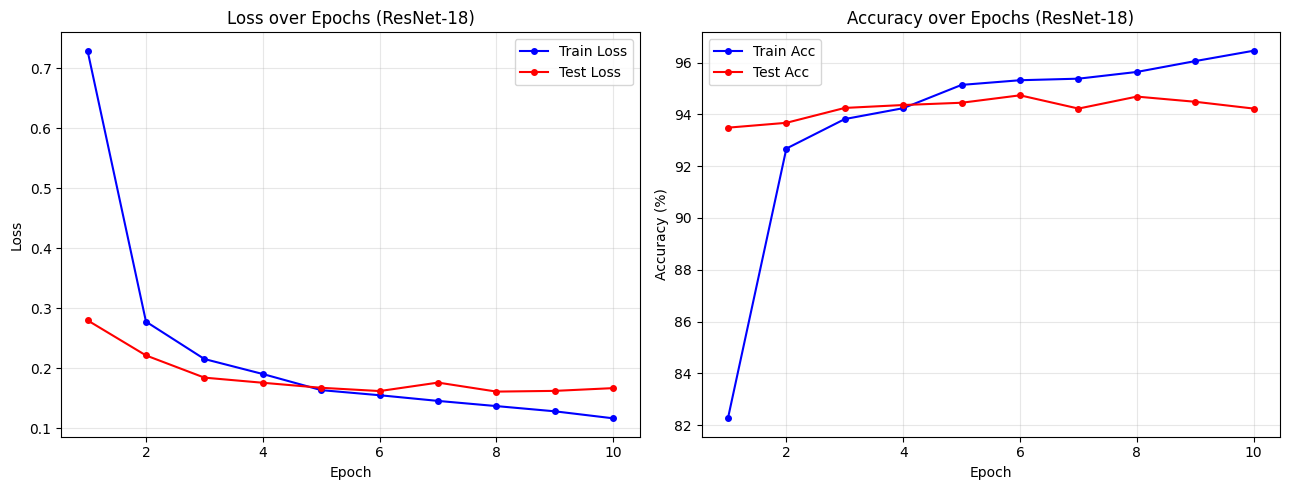

In [59]:
epochs = range(1, NUM_EPOCHS + 1);

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5));

# Loss plot
ax1.plot(epochs, history_resnet['train_loss'], 'b-o', markersize=4, label='Train Loss');
ax1.plot(epochs, history_resnet['test_loss'],  'r-o', markersize=4, label='Test Loss');
ax1.set_title('Loss over Epochs (ResNet-18)');
ax1.set_xlabel('Epoch');
ax1.set_ylabel('Loss');
ax1.legend();
ax1.grid(True, alpha=0.3);

# Accuracy plot
ax2.plot(epochs, history_resnet['train_acc'], 'b-o', markersize=4, label='Train Acc');
ax2.plot(epochs, history_resnet['test_acc'],  'r-o', markersize=4, label='Test Acc');
ax2.set_title('Accuracy over Epochs (ResNet-18)');
ax2.set_xlabel('Epoch');
ax2.set_ylabel('Accuracy (%)');
ax2.legend();
ax2.grid(True, alpha=0.3);

plt.tight_layout();
plt.savefig('resnet_training_curves.png', dpi=150, bbox_inches='tight');
plt.show();

In [60]:
!pip install grad-cam -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 84.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [61]:
from pytorch_grad_cam import GradCAM;
from pytorch_grad_cam.utils.image import show_cam_on_image;
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget;
import numpy as np;
import matplotlib.pyplot as plt;

# Select 2 correct and 2 incorrect predictions from test set
model_resnet.eval();

correct_images, correct_labels, correct_preds     = [], [], [];
incorrect_images, incorrect_labels, incorrect_preds = [], [], [];

with torch.no_grad():
    for images, labels in test_loader_stl:
        images, labels = images.to(device), labels.to(device);
        outputs = model_resnet(images);
        preds   = outputs.argmax(dim=1);

        for i in range(len(labels)):
            if preds[i] == labels[i] and len(correct_images) < 2:
                correct_images.append(images[i].cpu());
                correct_labels.append(labels[i].item());
                correct_preds.append(preds[i].item());

            if preds[i] != labels[i] and len(incorrect_images) < 2:
                incorrect_images.append(images[i].cpu());
                incorrect_labels.append(labels[i].item());
                incorrect_preds.append(preds[i].item());

        if len(correct_images) == 2 and len(incorrect_images) == 2:
            break;

print(f'Correct predictions:   {correct_preds}   True labels: {correct_labels}');
print(f'Incorrect predictions: {incorrect_preds} True labels: {incorrect_labels}');
print(f'Classes: {test_stl.classes}');

Correct predictions:   [6, 7]   True labels: [6, 7]
Incorrect predictions: [2, 6] True labels: [9, 5]
Classes: ['airplane', 'bird', 'car', 'cat', 'deer', 'dog', 'horse', 'monkey', 'ship', 'truck']


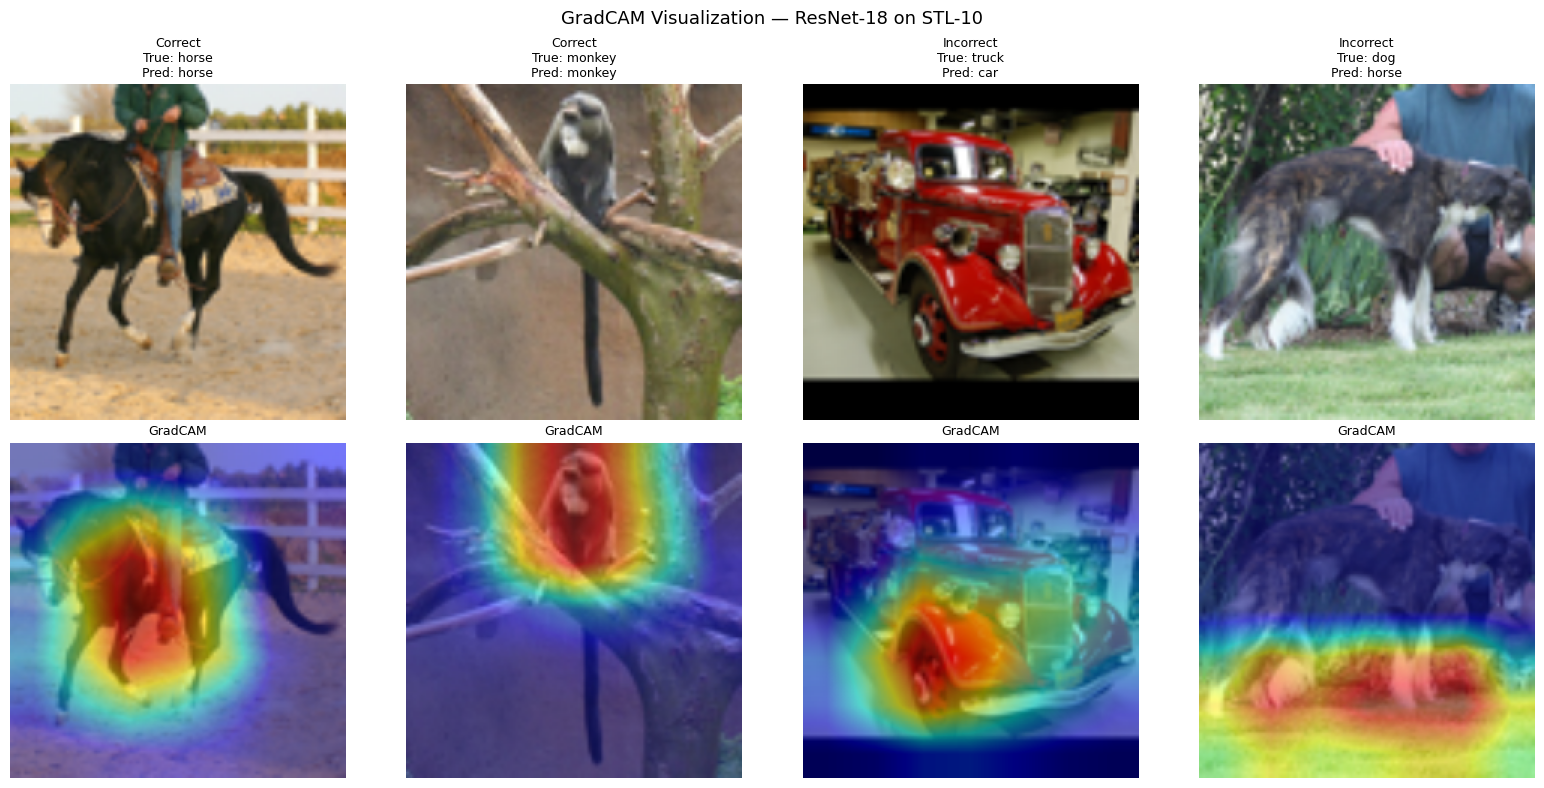

In [63]:
# Re-enable gradients for layer4 so GradCAM can work
for param in model_resnet.layer4.parameters():
    param.requires_grad = True

# Target layer — last conv layer of ResNet-18
target_layer = [model_resnet.layer4[-1]]

# Initialize GradCAM
cam = GradCAM(model=model_resnet, target_layers=target_layer)

# Combine all 4 images
all_images  = correct_images + incorrect_images
all_labels  = correct_labels + incorrect_labels
all_preds   = correct_preds  + incorrect_preds
all_titles  = ['Correct', 'Correct', 'Incorrect', 'Incorrect']

# ImageNet denormalization
mean = np.array([0.485, 0.456, 0.406])
std  = np.array([0.229, 0.224, 0.225])

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for i, (img_tensor, true_label, pred_label) in enumerate(zip(all_images, all_labels, all_preds)):
    input_tensor = img_tensor.unsqueeze(0).to(device)

    targets       = [ClassifierOutputTarget(pred_label)]
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0]

    # Denormalize
    img_np = img_tensor.permute(1, 2, 0).numpy()
    img_np = std * img_np + mean
    img_np = np.clip(img_np, 0, 1).astype(np.float32)

    # Overlay heatmap
    cam_image = show_cam_on_image(img_np, grayscale_cam, use_rgb=True)

    # Original image
    axes[0, i].imshow(img_np)
    axes[0, i].set_title(f'{all_titles[i]}\nTrue: {test_stl.classes[true_label]}\nPred: {test_stl.classes[pred_label]}', fontsize=9)
    axes[0, i].axis('off')

    # GradCAM heatmap
    axes[1, i].imshow(cam_image)
    axes[1, i].set_title('GradCAM', fontsize=9)
    axes[1, i].axis('off')

plt.suptitle('GradCAM Visualization — ResNet-18 on STL-10', fontsize=13)
plt.tight_layout()
plt.savefig('gradcam_results.png', dpi=150, bbox_inches='tight')
plt.show()